# Demand Forecasting for Supply Chain Optimization Using Historical Sales Data

## Predictive Analytics Project Using the KDD Methodology

**Objective:** To analyze historical retail sales, identify demand patterns, develop and compare machine learning regression models, and evaluate their performance to support inventory management and supply chain planning.

**Datasets:**
1. Store Item Demand Forecasting
2. Rossmann Store Sales

In [ ]:

from google.colab import files
import os
import zipfile

# Upload the Store Item Demand train.csv and Rossmann ZIP
uploaded = files.upload()

# Create a separate folder for Rossmann files
os.makedirs("/content/rossmann_data", exist_ok=True)

for filename in uploaded:
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(filename, "r") as zip_ref:
            zip_ref.extractall("/content/rossmann_data")
        print(f"Extracted Rossmann dataset: {filename}")

print("\nUploaded files:")
for filename in uploaded:
    print("-", filename)


Saving rossmann-store-sales.zip to rossmann-store-sales.zip
Extracted Rossmann dataset: rossmann-store-sales.zip

Uploaded files:
- rossmann-store-sales.zip


In [ ]:

import os

print("DATASET 1: Store Item Demand Forecasting")
print("Files in /content:")
print([f for f in os.listdir("/content") if f.endswith(".csv")])

print("\nDATASET 2: Rossmann Store Sales")
for root, dirs, files_list in os.walk("/content/rossmann_data"):
    for filename in files_list:
        if filename.endswith(".csv"):
            print(filename)


DATASET 1: Store Item Demand Forecasting
Files in /content:
[]

DATASET 2: Rossmann Store Sales
sample_submission.csv
test.csv
store.csv
train.csv


In [ ]:

from google.colab import files
import os
import zipfile

uploaded_demand = files.upload()

os.makedirs("/content/demand_data", exist_ok=True)

for filename in uploaded_demand:
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(filename, "r") as zip_ref:
            zip_ref.extractall("/content/demand_data")
        print("Extracted:", filename)

print("\nDataset 1 files:")
for root, dirs, filenames in os.walk("/content/demand_data"):
    for filename in filenames:
        print(filename)


Saving demand-forecasting-kernels-only.zip to demand-forecasting-kernels-only.zip
Extracted: demand-forecasting-kernels-only.zip

Dataset 1 files:
sample_submission.csv
test.csv
train.csv


In [ ]:

import os
import pandas as pd

# Find the training files
demand_train_path = None
rossmann_train_path = None

for root, dirs, filenames in os.walk("/content/demand_data"):
    if "train.csv" in filenames:
        demand_train_path = os.path.join(root, "train.csv")
        break

for root, dirs, filenames in os.walk("/content/rossmann_data"):
    if "train.csv" in filenames:
        rossmann_train_path = os.path.join(root, "train.csv")
        break

# Check that both training files exist
print("Demand training file:", demand_train_path)
print("Rossmann training file:", rossmann_train_path)

if demand_train_path is None or rossmann_train_path is None:
    raise FileNotFoundError(
        "A training file was not found. Check the extracted folders."
    )

# Load each dataset separately
demand_df = pd.read_csv(demand_train_path)
rossmann_df = pd.read_csv(rossmann_train_path)

print("\nDataset 1 shape:", demand_df.shape)
print("Dataset 2 shape:", rossmann_df.shape)


Demand training file: /content/demand_data/train.csv
Rossmann training file: /content/rossmann_data/train.csv

Dataset 1 shape: (913000, 4)
Dataset 2 shape: (1017209, 9)


/tmp/ipykernel_4894/3812333890.py:29: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  rossmann_df = pd.read_csv(rossmann_train_path)


In [ ]:

print("DATASET 1: Store Item Demand Forecasting")
display(demand_df.head())
print("Columns:", demand_df.columns.tolist())

print("\nDATASET 2: Rossmann Store Sales")
display(rossmann_df.head())
print("Columns:", rossmann_df.columns.tolist())


DATASET 1: Store Item Demand Forecasting


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


Columns: ['date', 'store', 'item', 'sales']

DATASET 2: Rossmann Store Sales


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


Columns: ['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']


# Step 2: Data Cleaning

Data cleaning is performed to improve data quality before applying machine learning algorithms. In this stage, both datasets are examined separately for missing values, duplicate records, incorrect data types and invalid sales values.

Only issues identified during inspection will be handled. This helps preserve valid historical sales information and ensures that the datasets are suitable for forecasting.

In [ ]:

print("DATASET 1: Store Item Demand Forecasting")
print("Missing values per column:")
print(demand_df.isnull().sum())

print("\nDATASET 2: Rossmann Store Sales")
print("Missing values per column:")
print(rossmann_df.isnull().sum())


DATASET 1: Store Item Demand Forecasting
Missing values per column:
date     0
store    0
item     0
sales    0
dtype: int64

DATASET 2: Rossmann Store Sales
Missing values per column:
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64


In [ ]:

print("DATASET 1: Store Item Demand Forecasting")
print("Duplicate rows:", demand_df.duplicated().sum())

print("\nDATASET 2: Rossmann Store Sales")
print("Duplicate rows:", rossmann_df.duplicated().sum())


DATASET 1: Store Item Demand Forecasting
Duplicate rows: 0

DATASET 2: Rossmann Store Sales
Duplicate rows: 0


In [ ]:

print("DATASET 1: Store Item Demand Forecasting")
print(demand_df.dtypes)
print("\nSales summary:")
print(demand_df["sales"].describe())

print("\nDATASET 2: Rossmann Store Sales")
print(rossmann_df.dtypes)
print("\nSales summary:")
print(rossmann_df["Sales"].describe())


DATASET 1: Store Item Demand Forecasting
date     object
store     int64
item      int64
sales     int64
dtype: object

Sales summary:
count    913000.000000
mean         52.250287
std          28.801144
min           0.000000
25%          30.000000
50%          47.000000
75%          70.000000
max         231.000000
Name: sales, dtype: float64

DATASET 2: Rossmann Store Sales
Store             int64
DayOfWeek         int64
Date             object
Sales             int64
Customers         int64
Open              int64
Promo             int64
StateHoliday     object
SchoolHoliday     int64
dtype: object

Sales summary:
count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64


## Step 2: Data Cleaning

Both datasets were checked for missing values and duplicate records. No missing values or duplicate rows were found. The date columns will be converted to datetime format, and sales values will be checked before feature engineering.

In [ ]:

# Convert dates and ensure sales columns are numeric
demand_df["date"] = pd.to_datetime(demand_df["date"])
rossmann_df["Date"] = pd.to_datetime(rossmann_df["Date"])

demand_df["sales"] = pd.to_numeric(demand_df["sales"])
rossmann_df["Sales"] = pd.to_numeric(rossmann_df["Sales"])

print("Dataset 1 cleaned:", demand_df.shape)
print("Dataset 2 cleaned:", rossmann_df.shape)


Dataset 1 cleaned: (913000, 4)
Dataset 2 cleaned: (1017209, 9)


## Step 3: Data Transformation

The datasets are transformed into daily total sales series. Calendar variables and lagged sales features are created to help the models learn temporal patterns. The data is then divided chronologically into training and validation sets to prevent future information from leaking into training.

In [ ]:

def prepare_daily_data(df, date_col, sales_col):
    daily = (
        df.groupby(date_col, as_index=False)[sales_col]
        .sum()
        .sort_values(date_col)
        .rename(columns={date_col: "date", sales_col: "sales"})
    )

    daily["year"] = daily["date"].dt.year
    daily["month"] = daily["date"].dt.month
    daily["day"] = daily["date"].dt.day
    daily["day_of_week"] = daily["date"].dt.dayofweek
    daily["day_of_year"] = daily["date"].dt.dayofyear

    daily["lag_1"] = daily["sales"].shift(1)
    daily["lag_7"] = daily["sales"].shift(7)
    daily["lag_14"] = daily["sales"].shift(14)

    daily = daily.dropna().reset_index(drop=True)
    return daily

demand_daily = prepare_daily_data(demand_df, "date", "sales")
rossmann_daily = prepare_daily_data(rossmann_df, "Date", "Sales")

print("Dataset 1 daily records:", len(demand_daily))
print("Dataset 2 daily records:", len(rossmann_daily))

display(demand_daily.head())
display(rossmann_daily.head())


Dataset 1 daily records: 1812
Dataset 2 daily records: 928


,date,sales,year,month,day,day_of_week,day_of_year,lag_1,lag_7,lag_14
0,2013-01-15,13625,2013,1,15,1,15,11746.0,13560.0,13696.0
1,2013-01-16,13591,2013,1,16,2,16,13625.0,13878.0,13678.0
2,2013-01-17,14587,2013,1,17,3,17,13591.0,14642.0,14488.0
3,2013-01-18,15495,2013,1,18,4,18,14587.0,15633.0,15677.0
4,2013-01-19,16294,2013,1,19,5,19,15495.0,16679.0,16237.0


,date,sales,year,month,day,day_of_week,day_of_year,lag_1,lag_7,lag_14
0,2013-01-15,5512591,2013,1,15,1,15,5886788.0,8749437.0,97235.0
1,2013-01-16,5293020,2013,1,16,2,16,5512591.0,7746603.0,6949829.0
2,2013-01-17,5386564,2013,1,17,3,17,5293020.0,7751485.0,6347820.0
3,2013-01-18,6137010,2013,1,18,4,18,5386564.0,8039306.0,6638954.0
4,2013-01-19,6010192,2013,1,19,5,19,6137010.0,6017491.0,5951593.0


## Step 4: Data Mining

Five regression algorithms are trained independently on each dataset. The earlier 80% of observations are used for training, while the most recent 20% are reserved for validation. This allows model performance to be assessed on later sales observations.

In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

features = [
    "year", "month", "day", "day_of_week", "day_of_year",
    "lag_1", "lag_7", "lag_14"
]

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=12, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100, max_depth=12, random_state=42, n_jobs=-1
    )
}

def train_and_evaluate(daily, dataset_name):
    split = int(len(daily) * 0.8)

    train = daily.iloc[:split]
    valid = daily.iloc[split:]

    X_train, y_train = train[features], train["sales"]
    X_valid, y_valid = valid[features], valid["sales"]

    results = []
    predictions = {}

    for name, model in models.items():
        model.fit(X_train, y_train)
        pred = model.predict(X_valid)

        mae = mean_absolute_error(y_valid, pred)
        rmse = np.sqrt(mean_squared_error(y_valid, pred))
        wape = (
            np.abs(y_valid - pred).sum() / np.abs(y_valid).sum() * 100
            if np.abs(y_valid).sum() != 0 else np.nan
        )

        results.append({
            "Dataset": dataset_name,
            "Model": name,
            "MAE": mae,
            "RMSE": rmse,
            "WAPE (%)": wape,
            "R2": r2_score(y_valid, pred)
        })

        predictions[name] = pred

    return pd.DataFrame(results), valid, predictions

demand_results, demand_valid, demand_predictions = train_and_evaluate(
    demand_daily, "Store Item Demand"
)

rossmann_results, rossmann_valid, rossmann_predictions = train_and_evaluate(
    rossmann_daily, "Rossmann"
)

print("Dataset 1 results")
display(demand_results.sort_values("MAE"))

print("Dataset 2 results")
display(rossmann_results.sort_values("MAE"))


Dataset 1 results


,Dataset,Model,MAE,RMSE,WAPE (%),R2
4,Store Item Demand,Extra Trees,540.579350,898.449699,1.834913,0.980755
3,Store Item Demand,Gradient Boosting,599.697655,929.086833,2.035580,0.979420
2,Store Item Demand,Random Forest,606.675567,1033.397755,2.059266,0.974540
1,Store Item Demand,Decision Tree,833.341117,1416.524712,2.828647,0.952162
0,Store Item Demand,Linear Regression,1075.590952,1675.987514,3.650926,0.933032


Dataset 2 results


,Dataset,Model,MAE,RMSE,WAPE (%),R2
4,Rossmann,Extra Trees,7.248809e+05,1.332483e+06,10.945490,0.828052
2,Rossmann,Random Forest,7.519358e+05,1.434824e+06,11.354011,0.800625
3,Rossmann,Gradient Boosting,8.166292e+05,1.463634e+06,12.330863,0.792538
1,Rossmann,Decision Tree,9.111493e+05,1.779977e+06,13.758088,0.693167
0,Rossmann,Linear Regression,1.402377e+06,2.041933e+06,21.175478,0.596210


## Step 5: Interpretation and Evaluation

Model performance is evaluated using MAE, RMSE, WAPE and R². The results are compared separately for each dataset, and the best-performing model is selected based on validation performance. Actual and predicted sales are visualized to understand forecasting errors and trends.

Best Dataset 1 model: Extra Trees
Dataset 1 MAE: 540.58

Best Dataset 2 model: Extra Trees
Dataset 2 MAE: 724880.89


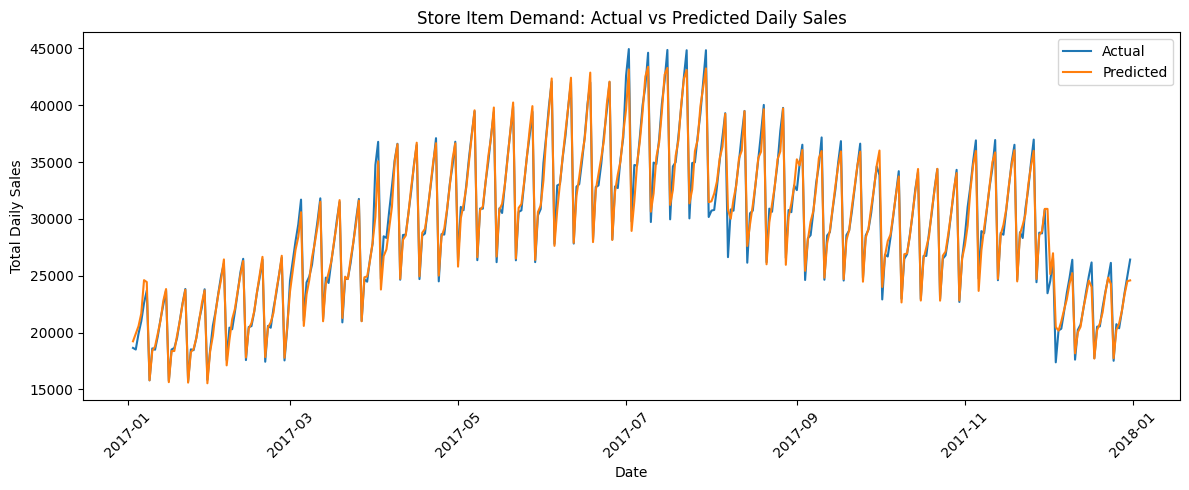

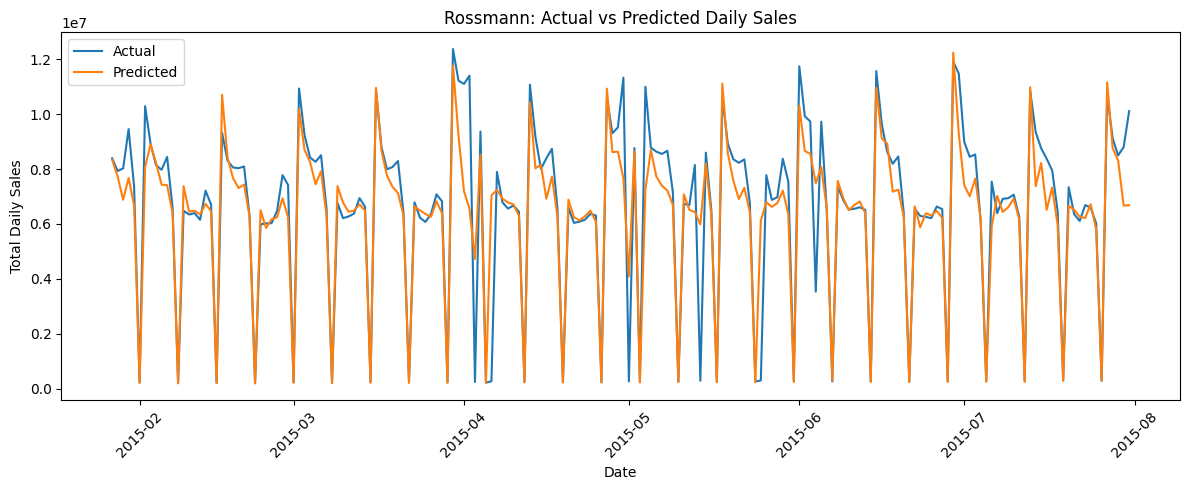

In [ ]:

import matplotlib.pyplot as plt

best_demand = demand_results.sort_values("MAE").iloc[0]
best_rossmann = rossmann_results.sort_values("MAE").iloc[0]

print("Best Dataset 1 model:", best_demand["Model"])
print("Dataset 1 MAE:", round(best_demand["MAE"], 2))

print("\nBest Dataset 2 model:", best_rossmann["Model"])
print("Dataset 2 MAE:", round(best_rossmann["MAE"], 2))

# Plot Dataset 1
plt.figure(figsize=(12, 5))
plt.plot(demand_valid["date"], demand_valid["sales"], label="Actual")
plt.plot(
    demand_valid["date"],
    demand_predictions[best_demand["Model"]],
    label="Predicted"
)
plt.title("Store Item Demand: Actual vs Predicted Daily Sales")
plt.xlabel("Date")
plt.ylabel("Total Daily Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot Dataset 2
plt.figure(figsize=(12, 5))
plt.plot(rossmann_valid["date"], rossmann_valid["sales"], label="Actual")
plt.plot(
    rossmann_valid["date"],
    rossmann_predictions[best_rossmann["Model"]],
    label="Predicted"
)
plt.title("Rossmann: Actual vs Predicted Daily Sales")
plt.xlabel("Date")
plt.ylabel("Total Daily Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Step 6: Knowledge Presentation

The final findings are presented through model comparison tables and actual-versus-predicted graphs. The best model for each dataset is identified using validation results. Conclusions discuss forecasting performance, limitations and potential benefits for inventory planning and supply chain optimization.

In [ ]:

all_results = pd.concat(
    [demand_results, rossmann_results],
    ignore_index=True
)

display(
    all_results.sort_values(["Dataset", "MAE"]).reset_index(drop=True)
)


,Dataset,Model,MAE,RMSE,WAPE (%),R2
0,Rossmann,Extra Trees,7.248809e+05,1.332483e+06,10.945490,0.828052
1,Rossmann,Random Forest,7.519358e+05,1.434824e+06,11.354011,0.800625
2,Rossmann,Gradient Boosting,8.166292e+05,1.463634e+06,12.330863,0.792538
3,Rossmann,Decision Tree,9.111493e+05,1.779977e+06,13.758088,0.693167
4,Rossmann,Linear Regression,1.402377e+06,2.041933e+06,21.175478,0.596210
5,Store Item Demand,Extra Trees,5.405793e+02,8.984497e+02,1.834913,0.980755
6,Store Item Demand,Gradient Boosting,5.996977e+02,9.290868e+02,2.035580,0.979420
7,Store Item Demand,Random Forest,6.066756e+02,1.033398e+03,2.059266,0.974540
8,Store Item Demand,Decision Tree,8.333411e+02,1.416525e+03,2.828647,0.952162
9,Store Item Demand,Linear Regression,1.075591e+03,1.675988e+03,3.650926,0.933032


## Conclusion

The project applied the six-step KDD methodology to two retail sales datasets and compared five machine learning regression models. The Extra Trees Regressor achieved the best results on both datasets, with R² scores of 0.9808 and 0.8281, respectively. The results demonstrate that machine learning can support demand forecasting and help improve inventory management and supply chain planning.